# Applying Hadoop Technologies to E-Commerce Order Data
## Stage 1 — Data Profiling, Quality Assessment, Cleaning and Preprocessing

**Course:** ITS66904 – Big Data Technologies  
**Notebook:** `Ecommerce_BigData_Preprocessing.ipynb`  
**Source of truth:** `ecommerce_customer_behavior_dataset_v2.csv` (17,049 records; 18 columns) — never modified by this notebook.

### Purpose
This notebook produces a reliable, validated dataset for the later Hadoop MapReduce and Hive stages. It does **not** write the academic report and does **not** claim that Hadoop or Hive jobs were executed.

### What this notebook does
1. Loads the original dataset (Google Drive, Colab upload, or local path).
2. Profiles every column and reports actual observed values.
3. Investigates completeness, uniqueness, consistency, validity, financial accuracy and identifier semantics.
4. Analyses IQR outliers without automatically deleting them.
5. Applies only cleaning operations justified by the observed evidence.
6. Adds derived analytical fields and validates the prepared dataset.
7. Exports six output files used by the Hadoop and Hive stages.

### Important findings established by the investigation (see Section 3)
- The dataset is **already complete and internally consistent** on conventional dimensions (no missing values, no duplicate rows, no invalid dates, no category label variants, no financial mismatches). These checks are reported as *passed*, not invented as problems.
- The `Order_ID` prefix is **1:1 with `Customer_ID`** and spans many dates and payment methods. It is a **customer order-group key**, not a single purchase order. The row-level `Order_ID` is the transaction unit.
- `Is_Returning_Customer` varies within a customer only as a legitimate **False → True temporal progression**; it is not corrected.
- Outliers in price/discount/amount/delivery are **statistically unusual but valid**; they are flagged and retained.

### Running in Google Colab
- Either mount Drive and place the CSV at `MyDrive/Ecommerce_BigData_Project/Dataset/`, or let the loader prompt you to upload it.
- Run all cells (`Runtime → Run all`). Outputs are written to a `Prepared/` folder next to the source CSV.

## 1. Import libraries and load the dataset

The loader tries, in order: a Drive folder, `/content`, the local project `Dataset/` folder, and finally a Colab file upload. The original file is read twice:
- `df_raw` — with pandas type inference, used for statistical work;
- `df_text` — all values as strings, used for honest checks of empty strings, whitespace and formatting.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 13,
                     "axes.labelsize": 11, "figure.autolayout": True})

DATASET_NAME = "ecommerce_customer_behavior_dataset_v2.csv"
FINANCIAL_TOLERANCE = 0.01   # currency amounts are stored to 2 decimal places

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.10.3 | seaborn 0.13.2


In [2]:
def locate_source_csv():
    """Locate the original CSV in Colab or in a local project folder."""
    candidates = []
    # Google Drive is only used if it is already mounted.
    if Path("/content/drive/MyDrive").exists():
        candidates.append(Path("/content/drive/MyDrive/Ecommerce_BigData_Project/Dataset") / DATASET_NAME)
    candidates += [
        Path("/content") / DATASET_NAME,
        Path.cwd() / "Dataset" / DATASET_NAME,
        Path.cwd() / DATASET_NAME,
        Path.cwd().parent / "Dataset" / DATASET_NAME,
        Path("D:/Ecommerce_BigData_Project/Ecommerce_BigData_Project/Dataset") / DATASET_NAME,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    # Last resort in Google Colab: interactive upload.
    try:
        from google.colab import files
        print("Please upload", DATASET_NAME, "when prompted.")
        uploaded = files.upload()
        return Path(next(iter(uploaded))).resolve()
    except Exception as exc:
        raise FileNotFoundError(
            "Could not locate " + DATASET_NAME + ". Mount Google Drive or upload the file."
        ) from exc

SOURCE = locate_source_csv()
OUTPUT_DIR = SOURCE.parent / "Prepared"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Source file :", SOURCE)
print("Output folder:", OUTPUT_DIR)

df_raw = pd.read_csv(SOURCE)
df_text = pd.read_csv(SOURCE, dtype=str, keep_default_na=False)

Source file : D:\Ecommerce_BigData_Project\Ecommerce_BigData_Project\Dataset\ecommerce_customer_behavior_dataset_v2.csv
Output folder: D:\Ecommerce_BigData_Project\Ecommerce_BigData_Project\Dataset\Prepared


In [3]:
display(Markdown("#### First five records"))
display(df_raw.head())
display(Markdown("#### Last five records"))
display(df_raw.tail())

n_records, n_columns = df_raw.shape
display(Markdown(
    "#### Shape and confirmation\n"
    f"- Records (rows): **{n_records:,}**\n"
    f"- Columns: **{n_columns}**\n"
    "- Header row excluded from the record count."
))

display(Markdown("#### Column names (in file order)"))
display(pd.DataFrame({"Position": range(n_columns), "Column": list(df_raw.columns)}))

display(Markdown("#### Inferred data types"))
display(df_raw.dtypes.rename("Inferred dtype").to_frame())

#### First five records

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


#### Last five records

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
17044,ORD_004999-1,CUST_04999,2024-01-16,44,Male,Antalya,Beauty,68.65,2,0.00,137.30,Digital Wallet,Mobile,14,10,False,6,1
17045,ORD_005000-1,CUST_05000,2023-02-22,24,Female,Eskisehir,Beauty,156.12,1,0.00,156.12,Credit Card,Mobile,15,8,True,7,5
17046,ORD_005000-2,CUST_05000,2023-06-29,24,Female,Eskisehir,Home & Garden,1065.24,3,0.00,3195.72,Credit Card,Desktop,17,11,True,5,4
17047,ORD_005000-3,CUST_05000,2023-12-29,24,Female,Eskisehir,Books,47.73,2,8.80,86.66,Credit Card,Desktop,13,11,True,12,2
17048,ORD_005000-4,CUST_05000,2024-01-19,24,Female,Eskisehir,Home & Garden,1015.23,4,217.01,3843.91,Credit Card,Mobile,15,7,True,3,4


#### Shape and confirmation
- Records (rows): **17,049**
- Columns: **18**
- Header row excluded from the record count.

#### Column names (in file order)

,Position,Column
0,0,Order_ID
1,1,Customer_ID
2,2,Date
3,3,Age
4,4,Gender
5,5,City
6,6,Product_Category
7,7,Unit_Price
8,8,Quantity
9,9,Discount_Amount


#### Inferred data types

,Inferred dtype
Order_ID,str
Customer_ID,str
Date,str
Age,int64
Gender,str
City,str
Product_Category,str
Unit_Price,float64
Quantity,int64
Discount_Amount,float64


## 2. Initial data profiling

All results below are measured from the original file. Nothing is assumed.

In [4]:
missing_tbl = pd.DataFrame({
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Pct": (df_raw.isna().mean() * 100).round(4),
})
missing_tbl.loc["TOTAL"] = [int(missing_tbl["Missing_Count"].sum()),
                            round(float(missing_tbl["Missing_Pct"].sum()), 4)]
display(Markdown("#### 2.1 Missing values by column"))
display(missing_tbl)
initial_missing_total = int(df_raw.isna().sum().sum())

#### 2.1 Missing values by column

,Missing_Count,Missing_Pct
Order_ID,0.0,0.0
Customer_ID,0.0,0.0
Date,0.0,0.0
Age,0.0,0.0
Gender,0.0,0.0
City,0.0,0.0
Product_Category,0.0,0.0
Unit_Price,0.0,0.0
Quantity,0.0,0.0
Discount_Amount,0.0,0.0


In [5]:
empty_mask = df_text.apply(lambda s: s.str.strip() == "")
ws_mask = df_text.apply(lambda s: s != s.str.strip())
format_tbl = pd.DataFrame({
    "Empty_String_Count": empty_mask.sum(),
    "Leading_Trailing_Whitespace_Count": ws_mask.sum(),
    "Distinct_Text_Values": df_text.nunique(),
})
format_tbl.loc["TOTAL"] = [int(format_tbl["Empty_String_Count"].sum()),
                           int(format_tbl["Leading_Trailing_Whitespace_Count"].sum()),
                           ""]
display(Markdown("#### 2.2 Empty strings, whitespace and distinct values"))
display(format_tbl)
initial_empty_total = int(empty_mask.sum().sum())
initial_ws_total = int(ws_mask.sum().sum())

#### 2.2 Empty strings, whitespace and distinct values

,Empty_String_Count,Leading_Trailing_Whitespace_Count,Distinct_Text_Values
Order_ID,0,0,17049
Customer_ID,0,0,5000
Date,0,0,450
Age,0,0,57
Gender,0,0,3
City,0,0,10
Product_Category,0,0,8
Unit_Price,0,0,14711
Quantity,0,0,5
Discount_Amount,0,0,5526


In [6]:
initial_dup_rows = int(df_raw.duplicated().sum())
initial_dup_ids = int(df_raw["Order_ID"].duplicated().sum())
display(Markdown("#### 2.3 Duplicates"))
display(pd.DataFrame({
    "Check": ["Fully duplicated rows", "Duplicate row-level Order_ID values"],
    "Count": [initial_dup_rows, initial_dup_ids],
    "Distinct_Order_ID": [df_raw["Order_ID"].nunique(), df_raw["Order_ID"].nunique()],
}))

#### 2.3 Duplicates

,Check,Count,Distinct_Order_ID
0,Fully duplicated rows,0,17049
1,Duplicate row-level Order_ID values,0,17049


In [7]:
categorical_cols = ["Gender", "City", "Product_Category", "Payment_Method",
                    "Device_Type", "Is_Returning_Customer", "Customer_Rating"]
cat_rows = []
for col in categorical_cols:
    vals = sorted(df_text[col].unique().tolist())
    cat_rows.append({"Column": col, "Distinct_Values": len(vals),
                     "Observed_Values": ", ".join(vals)})
display(Markdown("#### 2.4 Categorical columns: distinct values"))
display(pd.DataFrame(cat_rows))

for col in ["Product_Category", "Payment_Method", "City"]:
    counts = df_raw[col].value_counts()
    display(Markdown(f"**Frequency distribution — {col}**"))
    display(pd.DataFrame({"Value": counts.index, "Records": counts.values,
                          "Percent": (counts.values / len(df_raw) * 100).round(2)}))

#### 2.4 Categorical columns: distinct values

,Column,Distinct_Values,Observed_Values
0,Gender,3,"Female, Male, Other"
1,City,10,"Adana, Ankara, Antalya, Bursa, Eskisehir, Gazi..."
2,Product_Category,8,"Beauty, Books, Electronics, Fashion, Food, Hom..."
3,Payment_Method,5,"Bank Transfer, Cash on Delivery, Credit Card, ..."
4,Device_Type,3,"Desktop, Mobile, Tablet"
5,Is_Returning_Customer,2,"False, True"
6,Customer_Rating,5,"1, 2, 3, 4, 5"


**Frequency distribution — Product_Category**

,Value,Records,Percent
0,Sports,2248,13.19
1,Beauty,2212,12.97
2,Books,2206,12.94
3,Food,2103,12.34
4,Toys,2090,12.26
5,Electronics,2074,12.16
6,Home & Garden,2060,12.08
7,Fashion,2056,12.06


**Frequency distribution — Payment_Method**

,Value,Records,Percent
0,Credit Card,6801,39.89
1,Debit Card,4321,25.34
2,Digital Wallet,3276,19.22
3,Bank Transfer,1763,10.34
4,Cash on Delivery,888,5.21


**Frequency distribution — City**

,Value,Records,Percent
0,Istanbul,4402,25.82
1,Ankara,2422,14.21
2,Izmir,2072,12.15
3,Bursa,1721,10.09
4,Adana,1326,7.78
5,Antalya,1246,7.31
6,Gaziantep,1183,6.94
7,Konya,1120,6.57
8,Kayseri,851,4.99
9,Eskisehir,706,4.14


In [8]:
numeric_cols = ["Age", "Unit_Price", "Quantity", "Discount_Amount", "Total_Amount",
                "Session_Duration_Minutes", "Pages_Viewed", "Delivery_Time_Days",
                "Customer_Rating"]
display(Markdown("#### 2.5 Numeric column summaries"))
display(df_raw[numeric_cols].describe().T.round(3))

date_parsed_raw = pd.to_datetime(df_raw["Date"], format="%Y-%m-%d", errors="coerce")
display(Markdown("#### 2.6 Date coverage"))
display(pd.DataFrame({
    "Check": ["Rows", "Parsed successfully", "Failed to parse", "Distinct dates",
              "Earliest date", "Latest date"],
    "Value": [len(df_raw), int(date_parsed_raw.notna().sum()),
              int(date_parsed_raw.isna().sum()), int(df_raw["Date"].nunique()),
              str(date_parsed_raw.min().date()), str(date_parsed_raw.max().date())],
}))
initial_invalid_dates = int(date_parsed_raw.isna().sum())

#### 2.5 Numeric column summaries

,count,mean,std,min,25%,50%,75%,max
Age,17049.0,34.946,11.047,18.00,26.00,35.00,42.00,75.00
Unit_Price,17049.0,447.902,722.320,5.05,73.26,174.68,494.57,7900.01
Quantity,17049.0,3.011,1.417,1.00,2.00,3.00,4.00,5.00
Discount_Amount,17049.0,69.788,240.705,0.00,0.00,0.00,32.71,6538.29
Total_Amount,17049.0,1277.439,2358.436,6.21,172.97,455.85,1267.75,37852.05
Session_Duration_Minutes,17049.0,14.536,2.926,4.00,13.00,15.00,17.00,26.00
Pages_Viewed,17049.0,9.003,2.260,1.00,7.00,9.00,11.00,18.00
Delivery_Time_Days,17049.0,6.504,3.489,1.00,4.00,6.00,8.00,25.00
Customer_Rating,17049.0,3.899,1.129,1.00,3.00,4.00,5.00,5.00


#### 2.6 Date coverage

,Check,Value
0,Rows,17049
1,Parsed successfully,17049
2,Failed to parse,0
3,Distinct dates,450
4,Earliest date,2023-01-01
5,Latest date,2024-03-25


## 3. Data quality investigation

Six dimensions are examined: completeness, uniqueness, consistency, validity, financial accuracy and identifier analysis. Each rule reports the number of records that **pass** and **fail**, and whether the rule is supported by dataset evidence or is an assumption requiring confirmation.

### 3.A Completeness

Missing values, empty strings and partially populated records are checked separately. No values are imputed; if a dimension passes, that is reported as a pass.

In [9]:
incomplete_rows = int(empty_mask.any(axis=1).sum())
completeness_tbl = pd.DataFrame({
    "Check": ["Missing cells (all columns)", "Empty / whitespace-only cells",
              "Rows with at least one empty cell", "Rows with at least one missing value"],
    "Count": [initial_missing_total, initial_empty_total, incomplete_rows,
              int(df_raw.isna().any(axis=1).sum())],
    "Finding": ["Pass — none found" if initial_missing_total == 0 else "Requires action",
                "Pass — none found" if initial_empty_total == 0 else "Requires action",
                "Pass — none found" if incomplete_rows == 0 else "Requires action",
                "Pass — none found" if df_raw.isna().any(axis=1).sum() == 0 else "Requires action"],
})
display(completeness_tbl)

,Check,Count,Finding
0,Missing cells (all columns),0,Pass — none found
1,Empty / whitespace-only cells,0,Pass — none found
2,Rows with at least one empty cell,0,Pass — none found
3,Rows with at least one missing value,0,Pass — none found


### 3.B Uniqueness

Row-level uniqueness is checked first. The identifier prefix is analysed separately in Section 3.F because it is a different grain of data.

In [10]:
display(pd.DataFrame({
    "Check": ["Fully duplicated rows", "Duplicate row-level Order_ID",
              "Distinct row-level Order_ID", "Distinct Customer_ID"],
    "Count": [initial_dup_rows, initial_dup_ids,
              int(df_raw["Order_ID"].nunique()), int(df_raw["Customer_ID"].nunique())],
    "Finding": ["Pass" if initial_dup_rows == 0 else "Requires action",
                "Pass" if initial_dup_ids == 0 else "Requires action",
                "One transaction per row-level ID", "Customers legitimately repeat"],
}))

,Check,Count,Finding
0,Fully duplicated rows,0,Pass
1,Duplicate row-level Order_ID,0,Pass
2,Distinct row-level Order_ID,17049,One transaction per row-level ID
3,Distinct Customer_ID,5000,Customers legitimately repeat


### 3.C Consistency

Two checks are performed: (i) inconsistent category representations such as capitalisation or surrounding spaces; (ii) conflicting attribute values inside one identifier prefix.

In [11]:
variant_rows = []
for col in categorical_cols:
    groups = {}
    for value in df_text[col].unique().tolist():
        groups.setdefault(value.strip().lower(), set()).add(value)
    variants = {k: sorted(v) for k, v in groups.items() if len(v) > 1}
    variant_rows.append({
        "Column": col,
        "Case_or_Space_Variant_Groups": len(variants),
        "Examples": str(variants)[:180] if variants else "None",
    })
category_variant_count = int(sum(r["Case_or_Space_Variant_Groups"] for r in variant_rows))
display(Markdown("#### 3.C.1 Category label representations"))
display(pd.DataFrame(variant_rows))

#### 3.C.1 Category label representations

,Column,Case_or_Space_Variant_Groups,Examples
0,Gender,0,None
1,City,0,None
2,Product_Category,0,None
3,Payment_Method,0,None
4,Device_Type,0,None
5,Is_Returning_Customer,0,None
6,Customer_Rating,0,None


In [12]:
# Temporary analytical columns for the prefix investigation.
id_parts = df_text["Order_ID"].str.extract(r"^(?P<Prefix>[^-]+)-(?P<Line>\d+)$")
tmp = df_text.copy()
tmp["Prefix"] = id_parts["Prefix"]
tmp["Line"] = pd.to_numeric(id_parts["Line"], errors="coerce")
prefix_group = tmp.groupby("Prefix")

conflict_tbl = pd.DataFrame({
    "Attribute": ["Customer_ID", "Date", "City", "Payment_Method",
                  "Product_Category", "Gender", "Age"],
    "Prefixes_With_Conflicting_Values": [
        int((prefix_group[c].nunique() > 1).sum()) for c in
        ["Customer_ID", "Date", "City", "Payment_Method", "Product_Category", "Gender", "Age"]
    ],
})
conflict_tbl["Total_Prefixes"] = len(prefix_group)
display(Markdown("#### 3.C.2 Conflicting values inside one identifier prefix"))
display(conflict_tbl)
display(Markdown(
    "> City, gender and age are constant inside a prefix; date, payment method and product category are not. "
    "This is the first indication that the prefix is not a single purchase event."
))

#### 3.C.2 Conflicting values inside one identifier prefix

,Attribute,Prefixes_With_Conflicting_Values,Total_Prefixes
0,Customer_ID,0,5000
1,Date,4103,5000
2,City,0,5000
3,Payment_Method,3635,5000
4,Product_Category,3942,5000
5,Gender,0,5000
6,Age,0,5000


> City, gender and age are constant inside a prefix; date, payment method and product category are not. This is the first indication that the prefix is not a single purchase event.

### 3.D Validity

Rules with a clear business meaning (positive quantity, non-negative money, discount not exceeding gross) are labelled as **business rules**. Ranges such as ratings 1–5 are labelled **assumption — confirm with the data owner** because no external documentation was supplied. No threshold is invented as a basis for deleting rows.

In [13]:
q = df_raw["Quantity"]
up = df_raw["Unit_Price"]
disc = df_raw["Discount_Amount"]
tot = df_raw["Total_Amount"]
gross_check = up * q
rating = df_raw["Customer_Rating"]
delivery = df_raw["Delivery_Time_Days"]
session = df_raw["Session_Duration_Minutes"]
age = df_raw["Age"]

validity_rules = [
    ("Quantity is a positive integer", int((q > 0).sum()), int((q <= 0).sum()), "Business rule"),
    ("Unit_Price is non-negative", int((up >= 0).sum()), int((up < 0).sum()), "Business rule"),
    ("Discount_Amount is non-negative", int((disc >= 0).sum()), int((disc < 0).sum()), "Business rule"),
    ("Discount_Amount <= Unit_Price * Quantity", int((disc <= gross_check).sum()),
     int((disc > gross_check).sum()), "Business rule"),
    ("Total_Amount is non-negative", int((tot >= 0).sum()), int((tot < 0).sum()), "Business rule"),
    ("Date parses as ISO YYYY-MM-DD", int(date_parsed_raw.notna().sum()),
     int(date_parsed_raw.isna().sum()), "Dataset format rule"),
    ("Customer_Rating within 1-5", int(rating.between(1, 5).sum()), int((~rating.between(1, 5)).sum()),
     "Assumption — confirm documented range"),
    ("Delivery_Time_Days is positive", int((delivery > 0).sum()), int((delivery <= 0).sum()),
     "Assumption — no delivery date to verify"),
    ("Session_Duration_Minutes is positive", int((session > 0).sum()), int((session <= 0).sum()),
     "Assumption — no external limit supplied"),
    ("Age is at least 18", int((age >= 18).sum()), int((age < 18).sum()),
     "Assumption — observed minimum is 18"),
]
validity_tbl = pd.DataFrame(validity_rules, columns=["Rule", "Pass", "Fail", "Basis"])
validity_tbl["Result"] = np.where(validity_tbl["Fail"] == 0, "PASS", "INVESTIGATE")
display(validity_tbl)

,Rule,Pass,Fail,Basis,Result
0,Quantity is a positive integer,17049,0,Business rule,PASS
1,Unit_Price is non-negative,17049,0,Business rule,PASS
2,Discount_Amount is non-negative,17049,0,Business rule,PASS
3,Discount_Amount <= Unit_Price * Quantity,17049,0,Business rule,PASS
4,Total_Amount is non-negative,17049,0,Business rule,PASS
5,Date parses as ISO YYYY-MM-DD,17049,0,Dataset format rule,PASS
6,Customer_Rating within 1-5,17049,0,Assumption — confirm documented range,PASS
7,Delivery_Time_Days is positive,17049,0,Assumption — no delivery date to verify,PASS
8,Session_Duration_Minutes is positive,17049,0,Assumption — no external limit supplied,PASS
9,Age is at least 18,17049,0,Assumption — observed minimum is 18,PASS


### 3.E Financial accuracy

The validated relationship from the earlier inspection is tested across all records:

`Total_Amount = (Unit_Price × Quantity) − Discount_Amount`

`Gross Sales` and `Net Sales` are kept distinct. The improved MapReduce and Hive implementations will use `Total_Amount` / `Net_Amount` for all sales figures.

In [14]:
gross_calc = (df_raw["Unit_Price"] * df_raw["Quantity"]).round(2)
net_calc = (gross_calc - df_raw["Discount_Amount"]).round(2)
amount_difference = (df_raw["Total_Amount"] - net_calc).round(6)
financial_mismatch = amount_difference.abs() > FINANCIAL_TOLERANCE
financial_mismatch_count = int(financial_mismatch.sum())

display(pd.DataFrame({
    "Metric": ["Tolerance", "Records checked", "Mismatches", "Max abs difference",
               "Gross sales (all rows)", "Net sales (all rows)"],
    "Value": [FINANCIAL_TOLERANCE, len(df_raw), financial_mismatch_count,
              float(amount_difference.abs().max()),
              round(float(gross_calc.sum()), 2), round(float(df_raw["Total_Amount"].sum()), 2)],
}))

if financial_mismatch_count:
    display(Markdown("**Mismatched records**"))
    display(df_raw.loc[financial_mismatch,
            ["Order_ID", "Unit_Price", "Quantity", "Discount_Amount",
             "Total_Amount"]].assign(Calculated_Net_Amount=net_calc[financial_mismatch],
                                     Difference=amount_difference[financial_mismatch]).head(20))
else:
    display(Markdown(
        "**Result: PASS.** All 17,049 records satisfy the financial rule within the tolerance. "
        "No financial correction is required."
    ))

,Metric,Value
0,Tolerance,0.01
1,Records checked,17049.00
2,Mismatches,0.00
3,Max abs difference,0.00
4,Gross sales (all rows),22968870.51
5,Net sales (all rows),21779052.59


**Result: PASS.** All 17,049 records satisfy the financial rule within the tolerance. No financial correction is required.

### 3.F Identifier analysis — what does `Order_ID` actually mean?

Hypotheses are tested against the data rather than assumed:

1. Is the prefix a **parent order** whose rows are product lines of one purchase?
2. Or is it a **customer order-group** whose rows are separate transactions?

Evidence required: one parent order should have one customer, one date, one city and one payment method if hypothesis 1 is true.

In [15]:
prefix_summary = pd.DataFrame({
    "Rows": prefix_group.size(),
    "Distinct_Customers": prefix_group["Customer_ID"].nunique(),
    "Distinct_Dates": prefix_group["Date"].nunique(),
    "Distinct_Cities": prefix_group["City"].nunique(),
    "Distinct_Payment_Methods": prefix_group["Payment_Method"].nunique(),
    "Distinct_Categories": prefix_group["Product_Category"].nunique(),
})
display(Markdown("#### 3.F.1 Distribution of rows per prefix"))
display(prefix_summary["Rows"].describe().round(2).to_frame().T)

display(Markdown("#### 3.F.2 Prefixes containing conflicting attribute values"))
display(pd.DataFrame({
    "Check": ["Prefixes with >1 row", "Prefixes with >1 customer", "Prefixes with >1 date",
              "Prefixes with >1 city", "Prefixes with >1 payment method",
              "Prefixes with >1 product category"],
    "Prefix_Count": [
        int((prefix_summary["Rows"] > 1).sum()),
        int((prefix_summary["Distinct_Customers"] > 1).sum()),
        int((prefix_summary["Distinct_Dates"] > 1).sum()),
        int((prefix_summary["Distinct_Cities"] > 1).sum()),
        int((prefix_summary["Distinct_Payment_Methods"] > 1).sum()),
        int((prefix_summary["Distinct_Categories"] > 1).sum()),
    ],
}))

#### 3.F.1 Distribution of rows per prefix

,count,mean,std,min,25%,50%,75%,max
Rows,5000.0,3.41,2.18,1.0,2.0,3.0,5.0,10.0


#### 3.F.2 Prefixes containing conflicting attribute values

,Check,Prefix_Count
0,Prefixes with >1 row,4108
1,Prefixes with >1 customer,0
2,Prefixes with >1 date,4103
3,Prefixes with >1 city,0
4,Prefixes with >1 payment method,3635
5,Prefixes with >1 product category,3942


In [16]:
cust_to_prefix = tmp.groupby("Customer_ID")["Prefix"].nunique()
prefix_to_cust = prefix_group["Customer_ID"].nunique()
contiguous = prefix_group["Line"].apply(
    lambda s: sorted(s.tolist()) == list(range(1, len(s) + 1)))
date_ordered = tmp.groupby("Prefix").apply(
    lambda g: g.sort_values("Line")["Date"].is_monotonic_increasing, include_groups=False)

# Returning-customer flag: is the within-customer variation a legitimate temporal progression?
tmp["_date"] = pd.to_datetime(tmp["Date"], format="%Y-%m-%d")
tmp["_ret"] = tmp["Is_Returning_Customer"].eq("True")
def flag_progression(g):
    g = g.sort_values("Line")
    flags = g["_ret"].tolist()
    return not any(cur and not nxt for cur, nxt in zip(flags, flags[1:]))
mixed_flags = tmp.groupby("Prefix")["Is_Returning_Customer"].nunique() > 1
mixed_prefixes = mixed_flags[mixed_flags].index
ret_progression = tmp[tmp["Prefix"].isin(mixed_prefixes)].groupby("Prefix").apply(
    flag_progression, include_groups=False)

display(Markdown("#### 3.F.3 Structural evidence"))
display(pd.DataFrame({
    "Test": ["Distinct prefixes", "Distinct customers", "Prefixes linked to exactly 1 customer",
             "Customers linked to exactly 1 prefix", "Prefixes with contiguous suffix 1..n",
             "Prefixes whose suffix order matches date order",
             "Mixed returning-customer prefixes with clean False -> True progression",
             "Suffix >= 2 rows flagged returning customer"],
    "Value": [int(tmp["Prefix"].nunique()), int(tmp["Customer_ID"].nunique()),
              int((prefix_to_cust == 1).sum()), int((cust_to_prefix == 1).sum()),
              int(contiguous.sum()), int(date_ordered.sum()),
              int(ret_progression.sum()),
              f"{int(tmp.loc[tmp['Line'] >= 2, '_ret'].sum()):,} / {int((tmp['Line'] >= 2).sum()):,}"],
}))

display(Markdown("#### 3.F.4 One illustrative group"))
display(tmp.loc[tmp["Prefix"] == "ORD_000001",
                ["Order_ID", "Customer_ID", "Date", "City", "Payment_Method", "Product_Category"]])

#### 3.F.3 Structural evidence

,Test,Value
0,Distinct prefixes,5000
1,Distinct customers,5000
2,Prefixes linked to exactly 1 customer,5000
3,Customers linked to exactly 1 prefix,5000
4,Prefixes with contiguous suffix 1..n,5000
5,Prefixes whose suffix order matches date order,5000
6,Mixed returning-customer prefixes with clean F...,1661
7,Suffix >= 2 rows flagged returning customer,"12,049 / 12,049"


#### 3.F.4 One illustrative group

,Order_ID,Customer_ID,Date,City,Payment_Method,Product_Category
0,ORD_000001-1,CUST_00001,2023-05-29,Ankara,Digital Wallet,Books
1,ORD_000001-2,CUST_00001,2023-10-12,Ankara,Credit Card,Home & Garden
2,ORD_000001-3,CUST_00001,2023-12-05,Ankara,Credit Card,Sports


In [17]:
order_identifier_analysis = pd.DataFrame([
    {"Metric": "Row-level Order_ID values", "Value": int(df_raw["Order_ID"].nunique()),
     "Interpretation": "One row = one transaction (product line). This is the order/transaction unit."},
    {"Metric": "Distinct Order_ID prefixes", "Value": int(tmp["Prefix"].nunique()),
     "Interpretation": "Customer order-group key, NOT a purchase order."},
    {"Metric": "Distinct Customer_ID values", "Value": int(tmp["Customer_ID"].nunique()),
     "Interpretation": "Prefix is 1:1 with customer; it is effectively a customer alias."},
    {"Metric": "Prefixes spanning more than one date", "Value": int((prefix_summary["Distinct_Dates"] > 1).sum()),
     "Interpretation": "Disproves the single-purchase parent-order interpretation."},
    {"Metric": "Prefixes spanning more than one payment method",
     "Value": int((prefix_summary["Distinct_Payment_Methods"] > 1).sum()),
     "Interpretation": "Payment method is transaction-level, not parent-order-level."},
    {"Metric": "Prefixes spanning more than one product category",
     "Value": int((prefix_summary["Distinct_Categories"] > 1).sum()),
     "Interpretation": "Rows are separate transactions, not lines of one basket."},
    {"Metric": "Prefixes with contiguous suffix 1..n", "Value": int(contiguous.sum()),
     "Interpretation": "Suffix is the customer's chronological transaction index."},
    {"Metric": "Recommended unit for order counts", "Value": "Row-level Order_ID",
     "Interpretation": "Use COUNT(DISTINCT Order_ID) = 17,049; never count prefixes as orders."},
    {"Metric": "Recommended use of prefix", "Value": "Customer_Order_Group_ID",
     "Interpretation": "Analytical grouping / customer-level segmentation only."},
])
display(Markdown("#### 3.F.5 Identifier analysis results (exported later)"))
display(order_identifier_analysis)

#### 3.F.5 Identifier analysis results (exported later)

,Metric,Value,Interpretation
0,Row-level Order_ID values,17049,One row = one transaction (product line). This...
1,Distinct Order_ID prefixes,5000,"Customer order-group key, NOT a purchase order."
2,Distinct Customer_ID values,5000,Prefix is 1:1 with customer; it is effectively...
3,Prefixes spanning more than one date,4103,Disproves the single-purchase parent-order int...
4,Prefixes spanning more than one payment method,3635,"Payment method is transaction-level, not paren..."
5,Prefixes spanning more than one product category,3942,"Rows are separate transactions, not lines of o..."
6,Prefixes with contiguous suffix 1..n,5000,Suffix is the customer's chronological transac...
7,Recommended unit for order counts,Row-level Order_ID,"Use COUNT(DISTINCT Order_ID) = 17,049; never c..."
8,Recommended use of prefix,Customer_Order_Group_ID,Analytical grouping / customer-level segmentat...


#### Conclusion of the identifier investigation

The parent-order interpretation is **not supported**. A prefix always belongs to one customer and one city, but it spans multiple dates, payment methods and categories, and its suffix is a contiguous chronological transaction index. Therefore:

- the **correct unit for order counts is the row-level `Order_ID`** (17,049 transactions);
- counting prefixes would report 5,000 and understate orders by a factor of about 3.4;
- the prefix is extracted as `Customer_Order_Group_ID` for customer-level grouping only.

This definition is used consistently in the Java MapReduce, Hive and comparison stages.

## 4. Numerical outlier analysis (IQR method)

For each numeric column: `IQR = Q3 − Q1`, `Lower = Q1 − 1.5×IQR`, `Upper = Q3 + 1.5×IQR`.

Outliers are **not deleted automatically**. Each column is classified as: genuine invalid value, statistically unusual but valid, or requiring further investigation. The evidence used for the classification is the validity and financial checks in Section 3.

In [18]:
outlier_columns = ["Unit_Price", "Quantity", "Discount_Amount", "Total_Amount",
                   "Session_Duration_Minutes", "Delivery_Time_Days", "Pages_Viewed", "Age"]
outlier_bounds = {}
outlier_rows = []

for col in outlier_columns:
    s = df_raw[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    outlier_bounds[col] = {"Q1": q1, "Q3": q3, "IQR": iqr, "Lower": lo, "Upper": hi}
    outlier_rows.append({
        "Column": col, "Q1": round(float(q1), 2), "Q3": round(float(q3), 2),
        "IQR": round(float(iqr), 2), "Lower_Bound": round(float(lo), 2),
        "Upper_Bound": round(float(hi), 2), "Min": float(s.min()), "Max": float(s.max()),
        "Outlier_Count": int(mask.sum()),
        "Outlier_Pct": round(float(mask.mean() * 100), 3),
    })

outlier_analysis = pd.DataFrame(outlier_rows)
assessments = {
    "Unit_Price": "Statistically unusual but valid: positive, finite, heavy-tailed prices; all financial rules pass.",
    "Quantity": "No outliers: values are integer 1-5.",
    "Discount_Amount": "Statistically unusual but valid: many zero discounts; discount never exceeds gross (Section 3.D/3.E).",
    "Total_Amount": "Statistically unusual but valid: follows from price x quantity - discount; no mismatches (Section 3.E).",
    "Session_Duration_Minutes": "Requires investigation: short/long sessions are plausible; no external limit supplied.",
    "Delivery_Time_Days": "Requires investigation: no delivery-date field is available to verify these values.",
    "Pages_Viewed": "Requires investigation: a single high value; no rule to declare it invalid.",
    "Age": "Statistically unusual but valid: all ages are plausible adults (18-75).",
}
outlier_analysis["Assessment"] = outlier_analysis["Column"].map(assessments)
display(Markdown("#### 4.1 IQR summary table"))
display(outlier_analysis)

#### 4.1 IQR summary table

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Min,Max,Outlier_Count,Outlier_Pct,Assessment
0,Unit_Price,73.26,494.57,421.31,-558.71,1126.54,5.05,7900.01,1757,10.306,"Statistically unusual but valid: positive, fin..."
1,Quantity,2.00,4.00,2.00,-1.00,7.00,1.00,5.00,0,0.000,No outliers: values are integer 1-5.
2,Discount_Amount,0.00,32.71,32.71,-49.06,81.78,0.00,6538.29,2789,16.359,Statistically unusual but valid: many zero dis...
3,Total_Amount,172.97,1267.75,1094.78,-1469.20,2909.92,6.21,37852.05,1943,11.397,Statistically unusual but valid: follows from ...
4,Session_Duration_Minutes,13.00,17.00,4.00,7.00,23.00,4.00,26.00,85,0.499,Requires investigation: short/long sessions ar...
5,Delivery_Time_Days,4.00,8.00,4.00,-2.00,14.00,1.00,25.00,475,2.786,Requires investigation: no delivery-date field...
6,Pages_Viewed,7.00,11.00,4.00,1.00,17.00,1.00,18.00,1,0.006,Requires investigation: a single high value; n...
7,Age,26.00,42.00,16.00,2.00,66.00,18.00,75.00,50,0.293,Statistically unusual but valid: all ages are ...


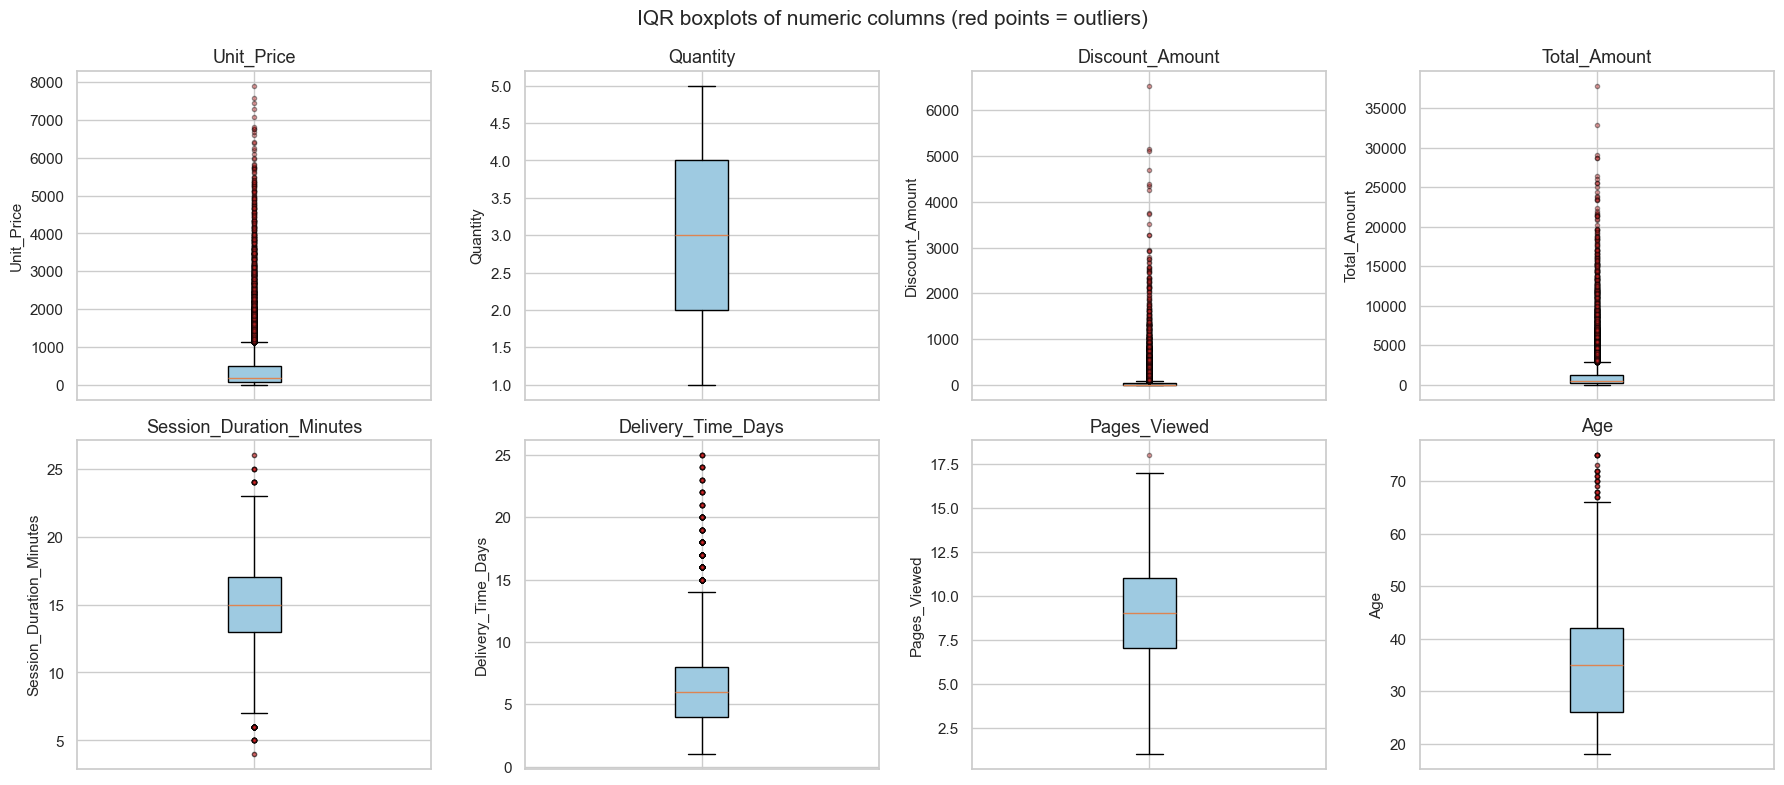

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), outlier_columns):
    ax.boxplot(df_raw[col].values, vert=True, patch_artist=True,
               boxprops={"facecolor": "#9ecae1"},
               flierprops={"marker": "o", "markersize": 3, "alpha": 0.4, "markerfacecolor": "#d62728"})
    ax.set_title(col)
    ax.set_ylabel(col)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)
fig.suptitle("IQR boxplots of numeric columns (red points = outliers)", fontsize=15)
plt.show()

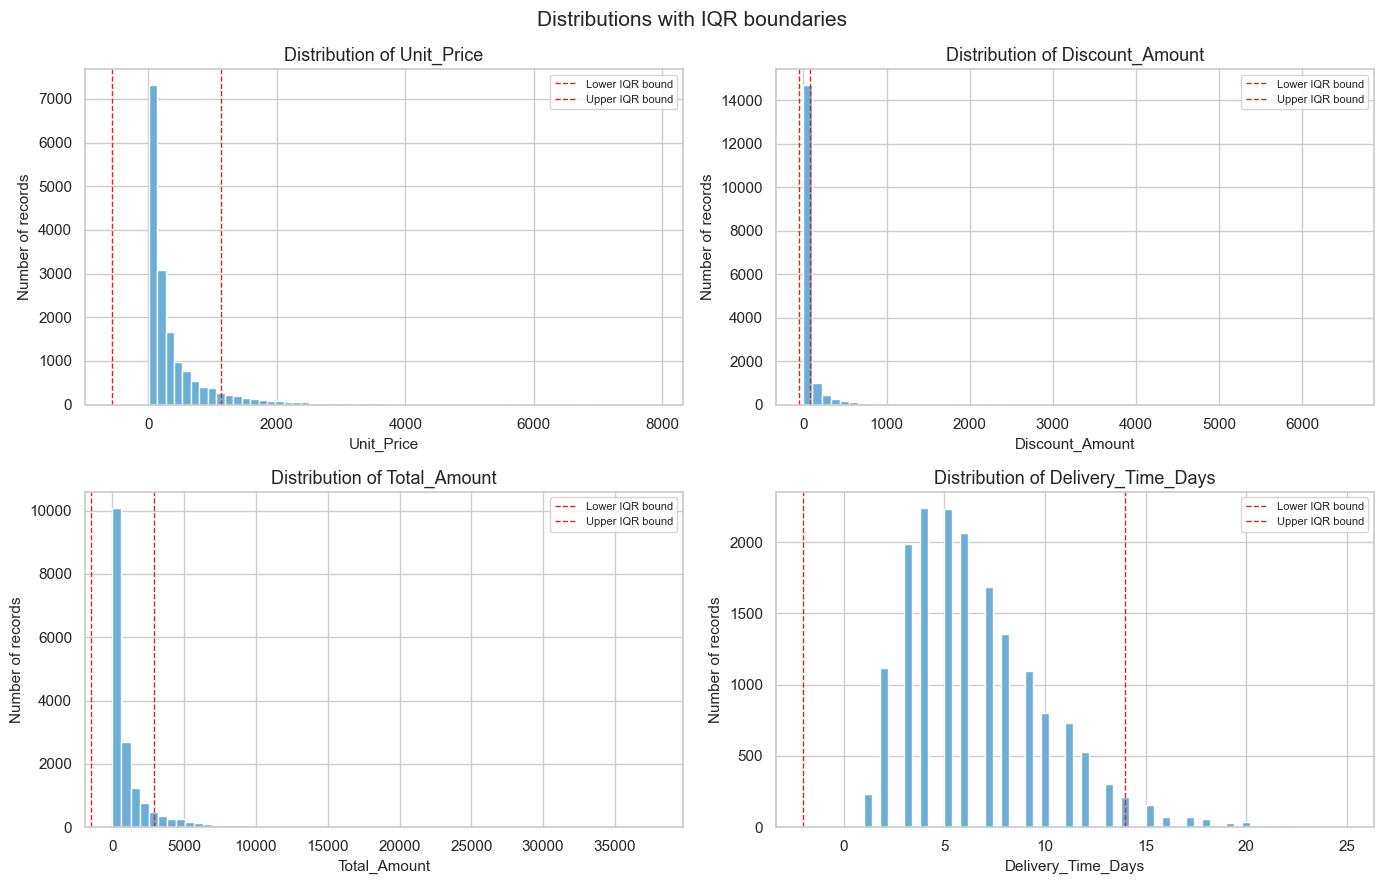

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ["Unit_Price", "Discount_Amount", "Total_Amount", "Delivery_Time_Days"]):
    ax.hist(df_raw[col], bins=60, color="#6baed6", edgecolor="white")
    b = outlier_bounds[col]
    ax.axvline(b["Lower"], color="#d62728", linestyle="--", linewidth=1, label="Lower IQR bound")
    ax.axvline(b["Upper"], color="#d62728", linestyle="--", linewidth=1, label="Upper IQR bound")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of records")
    ax.legend(fontsize=8)
fig.suptitle("Distributions with IQR boundaries", fontsize=15)
plt.show()

#### Outlier decision

No record is removed or altered in this section. Validity checks show that all monetary values satisfy the business rules, the discount never exceeds the gross amount, and ages and ratings are plausible. Outliers are therefore retained and recorded as boolean flags in the prepared dataset so downstream analyses can include or exclude them explicitly.

## 5. Data cleaning and preprocessing

Only operations justified by the observed evidence are applied. A log of every operation is kept and exported as `preprocessing_summary.csv`.

| # | Issue identified | Column(s) | Operation | Why | Records affected |
|---|---|---|---|---|---|
| 1 | Defensive formatting check found no whitespace problems | 8 text columns | Strip surrounding whitespace | Prevent label fragmentation in Hive | 0 |
| 2 | All 18 fields are untyped text in the source CSV; `Date` is ISO text; flags are text | Numeric, date and boolean columns | Convert to numeric, datetime and boolean types | Correct aggregation, sorting and range validation | 17,049 converted; 0 values rejected |
| 3 | Identifier mixes a customer-group prefix with a line suffix | `Order_ID` | Extract `Customer_Order_Group_ID` and `Order_Line_Number` | Avoid wrong order counts; preserve original ID | 17,049 |
| 4 | Outliers exist but none is invalid | 4 numeric columns | Add boolean outlier flags | Keep evidence without deleting data | 6,964 flags set |
| 5 | Sales must be net and consistent across tools | Monetary columns | Add `Gross_Amount` and `Net_Amount`; re-validate | Discounts must be accounted for | 17,049 |
| 6 | Text dates cannot be grouped by month reliably | `Date` | Add `Year`, `Month`, `Year_Month` | Support monthly Hive/MapReduce analysis | 17,049 |

At export time, boolean columns are written as lowercase `true`/`false` so that Hive BOOLEAN loads reliably (17,049 rows, values semantically unchanged).

**No records are removed and no values are fabricated.**

In [21]:
cleaning_log = []
df_clean = df_raw.copy()
initial_row_count = len(df_clean)

# --- Operation 1: whitespace standardisation (defensive; 0 affected) ---------
text_cols = ["Order_ID", "Customer_ID", "Gender", "City", "Product_Category",
             "Payment_Method", "Device_Type", "Is_Returning_Customer"]
ws_affected = 0
for col in text_cols:
    stripped = df_clean[col].astype(str).str.strip()
    ws_affected += int((stripped != df_clean[col].astype(str)).sum())
    df_clean[col] = stripped
cleaning_log.append({
    "Operation": "1. Strip surrounding whitespace", "Columns": ", ".join(text_cols),
    "Issue": "Defensive check for fragmented labels", "Action": "str.strip() applied",
    "Records_Affected": ws_affected, "Records_Removed": 0, "Records_Modified": ws_affected,
})
print("Operation 1 — whitespace corrections:", ws_affected)

# --- Operation 2: explicit typing -------------------------------------------
invalid_numeric_total = 0
for col in numeric_cols:
    before = df_clean[col].copy()
    df_clean[col] = pd.to_numeric(before, errors="coerce")
    invalid_numeric_total += int(df_clean[col].isna().sum() - before.isna().sum())

before_dates = df_clean["Date"].copy()
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%Y-%m-%d", errors="coerce")
invalid_dates_clean = int(df_clean["Date"].isna().sum() - before_dates.isna().sum())

bool_map = {"true": True, "false": False}
df_clean["Is_Returning_Customer"] = (
    df_clean["Is_Returning_Customer"].astype(str).str.strip().str.lower().map(bool_map)
)
invalid_booleans = int(df_clean["Is_Returning_Customer"].isna().sum())

cleaning_log.append({
    "Operation": "2. Explicit type conversion",
    "Columns": ", ".join(numeric_cols) + ", Date, Is_Returning_Customer",
    "Issue": "Untyped text in source CSV", "Action": "numeric / datetime / boolean conversion",
    "Records_Affected": int(len(df_clean)), "Records_Removed": 0,
    "Records_Modified": int(len(df_clean)),
})
print("Operation 2 — rejected numeric values:", invalid_numeric_total,
      "| rejected dates:", invalid_dates_clean, "| rejected booleans:", invalid_booleans)

assert invalid_numeric_total == 0 and invalid_dates_clean == 0 and invalid_booleans == 0, \
    "Unexpected invalid values introduced during conversion — investigate before proceeding."

Operation 1 — whitespace corrections: 0
Operation 2 — rejected numeric values: 0 | rejected dates: 0 | rejected booleans: 0


In [22]:
# --- Operation 3: identifier decomposition ----------------------------------
ids = df_clean["Order_ID"].str.extract(r"^(?P<Group>[^-]+)-(?P<Line>\d+)$")
df_clean["Customer_Order_Group_ID"] = ids["Group"]
df_clean["Order_Line_Number"] = ids["Line"].astype(int)
id_unparsed = int(df_clean["Customer_Order_Group_ID"].isna().sum())
cleaning_log.append({
    "Operation": "3. Extract identifier parts", "Columns": "Order_ID",
    "Issue": "Prefix is a customer group, not a purchase order",
    "Action": "Added Customer_Order_Group_ID and Order_Line_Number; original ID kept",
    "Records_Affected": int(len(df_clean) - id_unparsed), "Records_Removed": 0,
    "Records_Modified": 0,
})
print("Operation 3 — identifier values parsed:", len(df_clean) - id_unparsed,
      "| unparsed:", id_unparsed)

# --- Operation 5: outlier flags (rows retained) -----------------------------
flag_cols = {
    "Unit_Price": "Is_Unit_Price_Outlier",
    "Discount_Amount": "Is_Discount_Outlier",
    "Total_Amount": "Is_Total_Amount_Outlier",
    "Delivery_Time_Days": "Is_Delivery_Time_Outlier",
}
flags_set = 0
for source_col, flag_col in flag_cols.items():
    b = outlier_bounds[source_col]
    flag = (df_clean[source_col] < b["Lower"]) | (df_clean[source_col] > b["Upper"])
    df_clean[flag_col] = flag
    flags_set += int(flag.sum())
cleaning_log.append({
    "Operation": "4. Flag statistical outliers", "Columns": ", ".join(flag_cols.values()),
    "Issue": "Heavy-tailed but valid values", "Action": "Boolean flags added; no rows deleted",
    "Records_Affected": flags_set, "Records_Removed": 0, "Records_Modified": 0,
})
print("Operation 4 — outlier flags set:", flags_set)

# --- Operation 6: financial fields ------------------------------------------
df_clean["Gross_Amount"] = (df_clean["Unit_Price"] * df_clean["Quantity"]).round(2)
df_clean["Net_Amount"] = (df_clean["Gross_Amount"] - df_clean["Discount_Amount"]).round(2)
post_diff = (df_clean["Total_Amount"] - df_clean["Net_Amount"]).abs()
cleaning_log.append({
    "Operation": "5. Add gross and net sales", "Columns": "Gross_Amount, Net_Amount",
    "Issue": "Discounts must be reflected consistently in sales",
    "Action": "Derived fields added; Net_Amount re-validated against Total_Amount",
    "Records_Affected": int(len(df_clean)), "Records_Removed": 0, "Records_Modified": 0,
})
print("Operation 5 — financial mismatches after derivation:",
      int((post_diff > FINANCIAL_TOLERANCE).sum()))

# --- Operation 6: calendar fields -------------------------------------------
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Year_Month"] = df_clean["Date"].dt.strftime("%Y-%m")
cleaning_log.append({
    "Operation": "6. Add calendar fields", "Columns": "Year, Month, Year_Month",
    "Issue": "Text date cannot be grouped by month reliably",
    "Action": "Calendar parts derived from parsed Date",
    "Records_Affected": int(len(df_clean)), "Records_Removed": 0, "Records_Modified": 0,
})
print("Operation 6 — calendar fields added for", len(df_clean), "records")

assert len(df_clean) == initial_row_count, "Row count changed during cleaning"

Operation 3 — identifier values parsed: 17049 | unparsed: 0
Operation 4 — outlier flags set: 6964
Operation 5 — financial mismatches after derivation: 0
Operation 6 — calendar fields added for 17049 records


## 6. Data transformation and feature engineering

The prepared dataset uses a fixed column order so that the MapReduce programs and the Hive table can use identical positions. The first 18 columns are the original columns (typed); the remaining 11 are derived and clearly named.

In [23]:
ORIGINAL_COLUMNS = [
    "Order_ID", "Customer_ID", "Date", "Age", "Gender", "City", "Product_Category",
    "Unit_Price", "Quantity", "Discount_Amount", "Total_Amount", "Payment_Method",
    "Device_Type", "Session_Duration_Minutes", "Pages_Viewed", "Is_Returning_Customer",
    "Delivery_Time_Days", "Customer_Rating",
]
DERIVED_COLUMNS = [
    "Customer_Order_Group_ID", "Order_Line_Number", "Gross_Amount", "Net_Amount",
    "Year", "Month", "Year_Month", "Is_Unit_Price_Outlier", "Is_Discount_Outlier",
    "Is_Total_Amount_Outlier", "Is_Delivery_Time_Outlier",
]
FINAL_COLUMNS = ORIGINAL_COLUMNS + DERIVED_COLUMNS

df_prepared = df_clean[FINAL_COLUMNS].copy()

display(Markdown("#### Schema of the prepared dataset"))
schema_tbl = pd.DataFrame({
    "Position": range(len(FINAL_COLUMNS)),
    "Column": FINAL_COLUMNS,
    "Origin": ["Original (typed)"] * len(ORIGINAL_COLUMNS) + ["Derived"] * len(DERIVED_COLUMNS),
    "Dtype": [str(df_prepared[c].dtype) for c in FINAL_COLUMNS],
})
display(schema_tbl)
display(Markdown(f"Prepared shape: **{df_prepared.shape[0]:,} rows × {df_prepared.shape[1]} columns**"))

#### Schema of the prepared dataset

,Position,Column,Origin,Dtype
0,0,Order_ID,Original (typed),str
1,1,Customer_ID,Original (typed),str
2,2,Date,Original (typed),datetime64[us]
3,3,Age,Original (typed),int64
4,4,Gender,Original (typed),str
5,5,City,Original (typed),str
6,6,Product_Category,Original (typed),str
7,7,Unit_Price,Original (typed),float64
8,8,Quantity,Original (typed),int64
9,9,Discount_Amount,Original (typed),float64


Prepared shape: **17,049 rows × 29 columns**

## 7. Post-cleaning validation and before/after comparison

The same checks used in Sections 2 and 3 are repeated on the prepared dataset. Where nothing needed to change, the table records a pass rather than claiming an improvement.

In [24]:
prep_missing = int(df_prepared.isna().sum().sum())
prep_dup_rows = int(df_prepared.duplicated().sum())
prep_dup_ids = int(df_prepared["Order_ID"].duplicated().sum())
prep_invalid_num = int(sum(
    df_prepared[numeric_cols].apply(pd.to_numeric, errors="coerce").isna().sum()
))
prep_invalid_dates = int(df_prepared["Date"].isna().sum())
prep_fin_mismatch = int((df_prepared["Total_Amount"] - df_prepared["Net_Amount"]).abs().gt(FINANCIAL_TOLERANCE).sum())

variant_check = 0
for col in ["Gender", "City", "Product_Category", "Payment_Method", "Device_Type",
            "Is_Returning_Customer", "Customer_Order_Group_ID"]:
    vals = df_prepared[col].astype(str)
    groups = {}
    for v in vals.unique().tolist():
        groups.setdefault(v.strip().lower(), set()).add(v)
    variant_check += sum(1 for v in groups.values() if len(v) > 1)

comparison = pd.DataFrame([
    ["Record count", len(df_raw), len(df_prepared), "PASS — unchanged",
     "No rows deleted; all outliers retained"],
    ["Column count", df_raw.shape[1], df_prepared.shape[1], "Extended",
     "11 derived analytical columns added"],
    ["Missing cells", initial_missing_total, prep_missing, "PASS", "None in either dataset"],
    ["Fully duplicated rows", initial_dup_rows, prep_dup_rows, "PASS", "None in either dataset"],
    ["Duplicate Order_ID", initial_dup_ids, prep_dup_ids, "PASS", "Row-level ID remains unique"],
    ["Invalid numeric values", 0, prep_invalid_num, "PASS", "All numeric fields parse"],
    ["Invalid dates", initial_invalid_dates, prep_invalid_dates, "PASS", "All dates parse as ISO"],
    ["Category label variants", category_variant_count, variant_check, "PASS", "No case/space variants"],
    ["Financial mismatches", financial_mismatch_count, prep_fin_mismatch, "PASS",
     "Net amount equals Total_Amount within tolerance"],
    ["Gross vs net sales distinction", "Not present", "Both present", "Improved",
     "Prevents mixing gross and net sales downstream"],
    ["Order-count unit", "Ambiguous prefix", "Row-level Order_ID", "Resolved",
     "Prefix retained only as Customer_Order_Group_ID"],
], columns=["Check", "Before", "After", "Status", "Note"])
display(comparison)

# Consolidated machine-readable quality summary (exported in Section 9).
data_quality_summary = pd.DataFrame([
    ["Completeness", "Missing cells", initial_missing_total, "PASS"],
    ["Completeness", "Empty/whitespace-only cells", initial_empty_total, "PASS"],
    ["Uniqueness", "Fully duplicated rows", initial_dup_rows, "PASS"],
    ["Uniqueness", "Duplicate row-level Order_ID", initial_dup_ids, "PASS"],
    ["Consistency", "Category label variants", category_variant_count, "PASS"],
    ["Consistency", "Conflicting customer within prefix",
     int((prefix_summary["Distinct_Customers"] > 1).sum()), "PASS"],
    ["Consistency", "Conflicting city within prefix",
     int((prefix_summary["Distinct_Cities"] > 1).sum()), "PASS"],
    ["Consistency", "Mixed returning flag with reversal",
     int(len(ret_progression) - int(ret_progression.sum())), "PASS — legitimate temporal field"],
    ["Validity", "Business-rule failures", int(validity_tbl.loc[validity_tbl["Basis"].isin(
        ["Business rule", "Dataset format rule"]), "Fail"].sum()), "PASS"],
    ["Validity", "Assumption-rule failures", int(validity_tbl.loc[validity_tbl["Basis"].str.startswith(
        "Assumption"), "Fail"].sum()), "PASS — no violations observed"],
    ["Financial", "Amount mismatches (tolerance " + str(FINANCIAL_TOLERANCE) + ")",
     financial_mismatch_count, "PASS"],
    ["Outliers", "Records outside IQR bounds (all columns)",
     int(outlier_analysis["Outlier_Count"].sum()), "Retained and flagged — not deleted"],
    ["Identifier", "Prefixes spanning multiple dates",
     int((prefix_summary["Distinct_Dates"] > 1).sum()), "Customer group, not parent order"],
    ["Post-cleaning", "Missing cells", prep_missing, "PASS"],
    ["Post-cleaning", "Financial mismatches", prep_fin_mismatch, "PASS"],
], columns=["Dimension", "Check", "Observed_Value", "Assessment"])
display(Markdown("#### data_quality_summary.csv preview"))
display(data_quality_summary)

,Check,Before,After,Status,Note
0,Record count,17049,17049,PASS — unchanged,No rows deleted; all outliers retained
1,Column count,18,29,Extended,11 derived analytical columns added
2,Missing cells,0,0,PASS,None in either dataset
3,Fully duplicated rows,0,0,PASS,None in either dataset
4,Duplicate Order_ID,0,0,PASS,Row-level ID remains unique
5,Invalid numeric values,0,0,PASS,All numeric fields parse
6,Invalid dates,0,0,PASS,All dates parse as ISO
7,Category label variants,0,0,PASS,No case/space variants
8,Financial mismatches,0,0,PASS,Net amount equals Total_Amount within tolerance
9,Gross vs net sales distinction,Not present,Both present,Improved,Prevents mixing gross and net sales downstream


#### data_quality_summary.csv preview

,Dimension,Check,Observed_Value,Assessment
0,Completeness,Missing cells,0,PASS
1,Completeness,Empty/whitespace-only cells,0,PASS
2,Uniqueness,Fully duplicated rows,0,PASS
3,Uniqueness,Duplicate row-level Order_ID,0,PASS
4,Consistency,Category label variants,0,PASS
5,Consistency,Conflicting customer within prefix,0,PASS
6,Consistency,Conflicting city within prefix,0,PASS
7,Consistency,Mixed returning flag with reversal,0,PASS — legitimate temporal field
8,Validity,Business-rule failures,0,PASS
9,Validity,Assumption-rule failures,0,PASS — no violations observed


## 8. Visualisations

Each chart is included to answer a specific question about the data. Titles, axis labels and units are explicit.

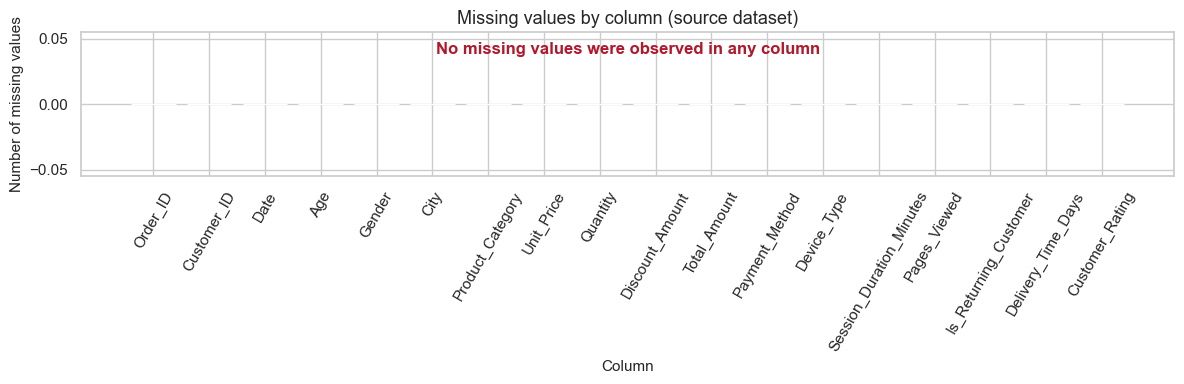

In [25]:
missing_series = df_raw.isna().sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(missing_series.index, missing_series.values, color="#7fcdbb")
ax.set_title("Missing values by column (source dataset)")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing values")
ax.tick_params(axis="x", rotation=60)
ax.text(0.5, 0.85, "No missing values were observed in any column",
        transform=ax.transAxes, ha="center", color="#b2182b", weight="bold")
plt.show()

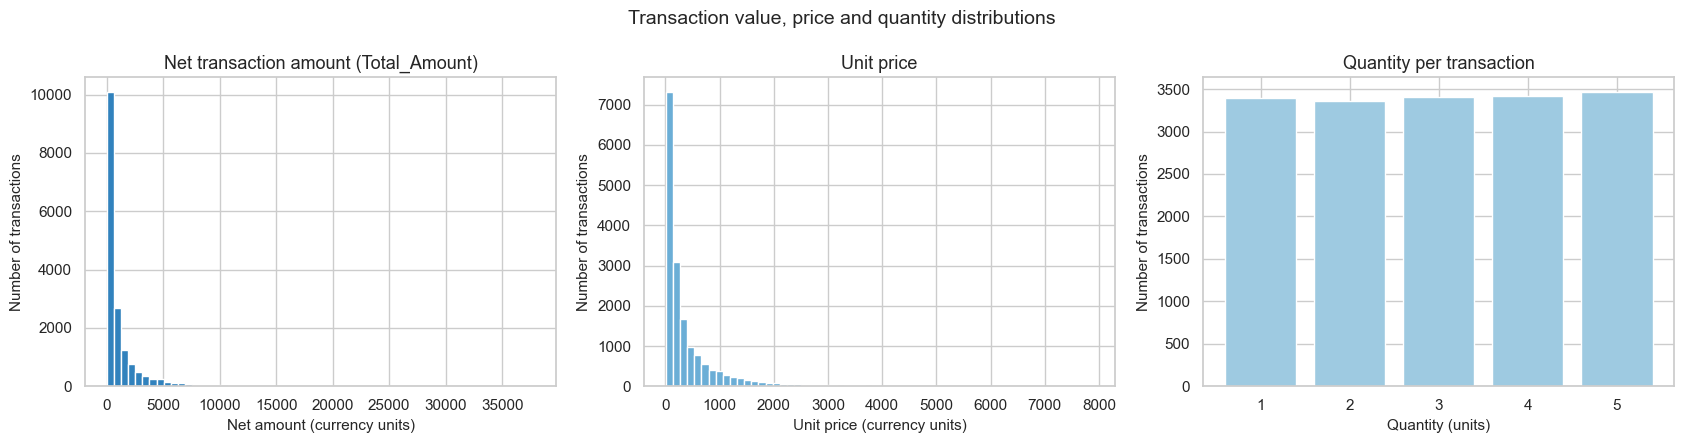

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(df_prepared["Total_Amount"], bins=60, color="#3182bd")
axes[0].set_title("Net transaction amount (Total_Amount)")
axes[0].set_xlabel("Net amount (currency units)")
axes[0].set_ylabel("Number of transactions")

axes[1].hist(df_prepared["Unit_Price"], bins=60, color="#6baed6")
axes[1].set_title("Unit price")
axes[1].set_xlabel("Unit price (currency units)")
axes[1].set_ylabel("Number of transactions")

qty = df_prepared["Quantity"].value_counts().sort_index()
axes[2].bar(qty.index.astype(str), qty.values, color="#9ecae1")
axes[2].set_title("Quantity per transaction")
axes[2].set_xlabel("Quantity (units)")
axes[2].set_ylabel("Number of transactions")
fig.suptitle("Transaction value, price and quantity distributions", fontsize=14)
plt.show()

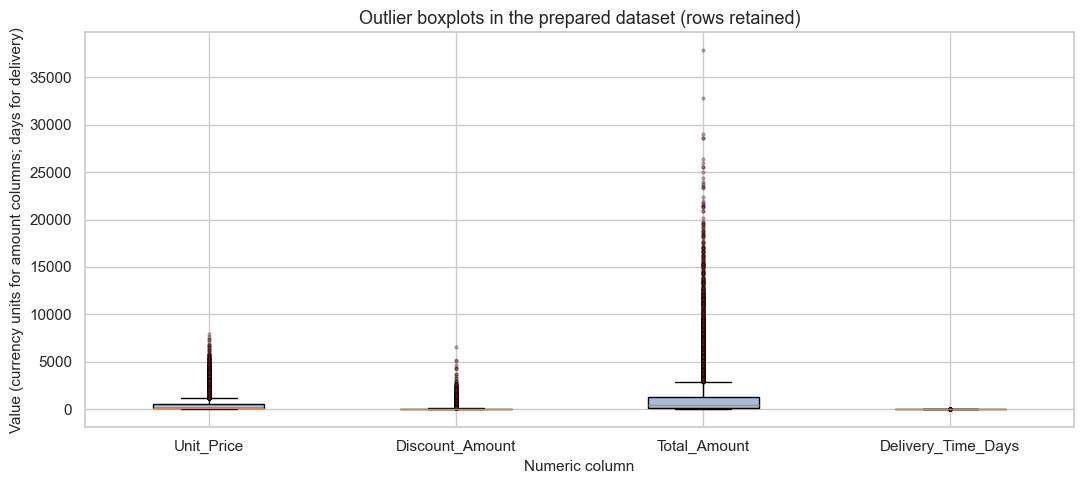

In [27]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([df_prepared[c].values for c in ["Unit_Price", "Discount_Amount",
                                            "Total_Amount", "Delivery_Time_Days"]],
           labels=["Unit_Price", "Discount_Amount", "Total_Amount", "Delivery_Time_Days"],
           patch_artist=True,
           boxprops={"facecolor": "#a6bddb"},
           flierprops={"marker": "o", "markersize": 2, "alpha": 0.3, "markerfacecolor": "#d62728"})
ax.set_title("Outlier boxplots in the prepared dataset (rows retained)")
ax.set_ylabel("Value (currency units for amount columns; days for delivery)")
ax.set_xlabel("Numeric column")
plt.show()

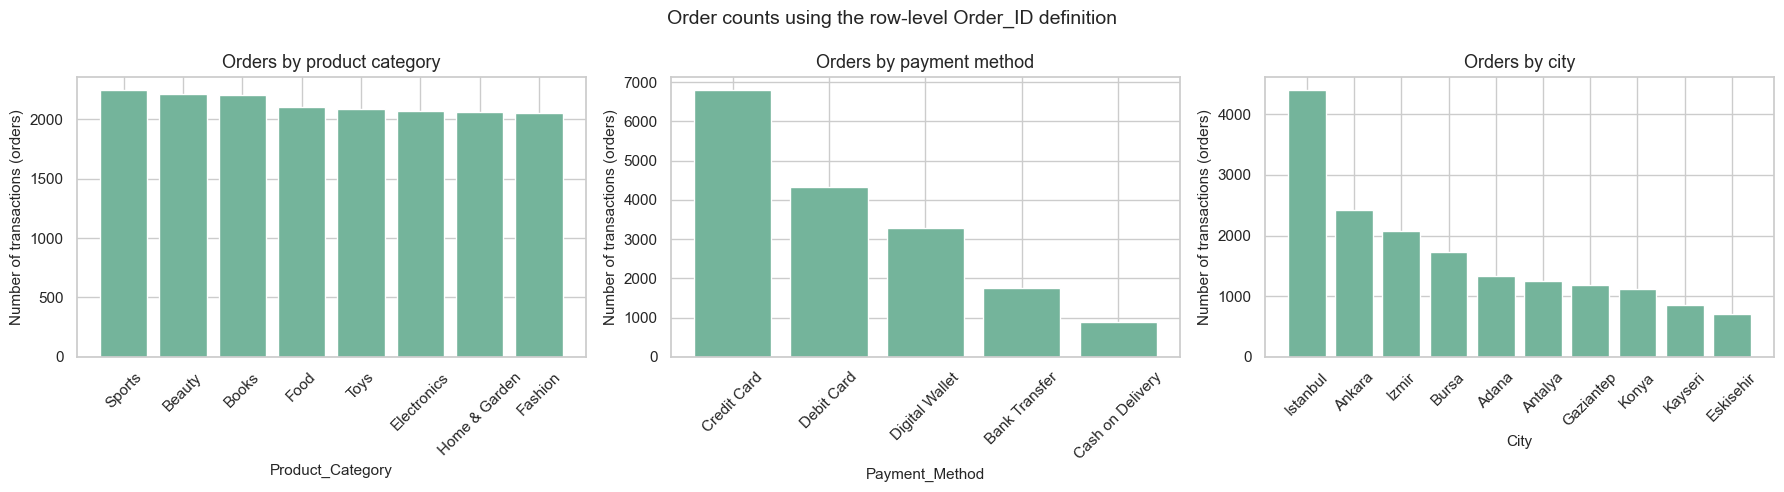

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(
        axes,
        ["Product_Category", "Payment_Method", "City"],
        ["Orders by product category", "Orders by payment method", "Orders by city"]):
    counts = df_prepared[col].value_counts()
    ax.bar(counts.index, counts.values, color="#74b49b")
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of transactions (orders)")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Order counts using the row-level Order_ID definition", fontsize=14)
plt.show()

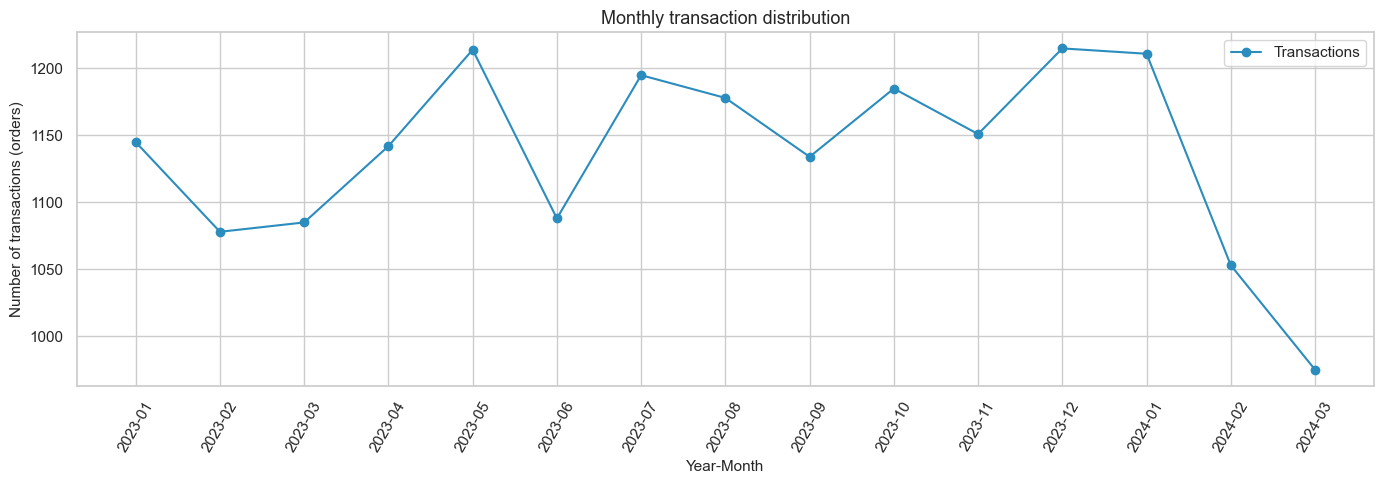

In [29]:
monthly = df_prepared.groupby("Year_Month").size().sort_index()
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly.index, monthly.values, marker="o", color="#2b8cbe", label="Transactions")
ax.set_title("Monthly transaction distribution")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Number of transactions (orders)")
ax.legend()
ax.tick_params(axis="x", rotation=60)
plt.show()

## 9. Export the final prepared datasets

Six files are written to the `Prepared/` folder next to the source CSV. The original dataset and the legacy cleaned files are left untouched.

| File | Purpose |
|---|---|
| `cleaned_ecommerce.csv` | Prepared dataset with header — used by Hive |
| `cleaned_ecommerce_noheader.csv` | Same data without header — used by MapReduce |
| `data_quality_summary.csv` | Measured quality checks and their assessment |
| `preprocessing_summary.csv` | Every cleaning operation and its effect |
| `outlier_analysis.csv` | IQR bounds, counts and classification |
| `order_identifier_analysis.csv` | Evidence for the order-count definition |

Boolean columns are exported as lowercase `true`/`false` so that Hive BOOLEAN and Java parsers read them reliably. Amounts are exported with exactly two decimal places.

In [30]:
df_export = df_prepared.copy()
for col in ["Is_Returning_Customer", "Is_Unit_Price_Outlier", "Is_Discount_Outlier",
            "Is_Total_Amount_Outlier", "Is_Delivery_Time_Outlier"]:
    df_export[col] = df_export[col].map({True: "true", False: "false"})

for col in ["Unit_Price", "Discount_Amount", "Total_Amount", "Gross_Amount", "Net_Amount"]:
    df_export[col] = df_export[col].map(lambda v: f"{v:.2f}")

outputs = {
    "cleaned_ecommerce.csv": df_export,
    "cleaned_ecommerce_noheader.csv": None,   # written separately without header
    "data_quality_summary.csv": data_quality_summary,
    "preprocessing_summary.csv": pd.DataFrame(cleaning_log),
    "outlier_analysis.csv": outlier_analysis,
    "order_identifier_analysis.csv": order_identifier_analysis,
}

for name, frame in outputs.items():
    if frame is not None:
        frame.to_csv(OUTPUT_DIR / name, index=False)

df_export.to_csv(OUTPUT_DIR / "cleaned_ecommerce_noheader.csv", index=False, header=False)

export_tbl = pd.DataFrame({
    "File": list(outputs.keys()),
    "Rows": [len(df_export), len(df_export), len(data_quality_summary),
             len(cleaning_log), len(outlier_analysis), len(order_identifier_analysis)],
    "Size_Bytes": [(OUTPUT_DIR / f).stat().st_size for f in outputs],
})
display(Markdown("#### Exported files"))
display(export_tbl)
print("Outputs saved to:", OUTPUT_DIR)

#### Exported files

,File,Rows,Size_Bytes
0,cleaned_ecommerce.csv,17049,3121219
1,cleaned_ecommerce_noheader.csv,17049,3120809
2,data_quality_summary.csv,15,870
3,preprocessing_summary.csv,6,1261
4,outlier_analysis.csv,8,1245
5,order_identifier_analysis.csv,9,989


Outputs saved to: D:\Ecommerce_BigData_Project\Ecommerce_BigData_Project\Dataset\Prepared


In [31]:
# Verification: read the prepared files back and confirm schema, types and integrity.
verify = pd.read_csv(OUTPUT_DIR / "cleaned_ecommerce.csv")
verify_text = pd.read_csv(OUTPUT_DIR / "cleaned_ecommerce.csv", dtype=str, keep_default_na=False)
checks = pd.DataFrame({
    "Check": ["Row count", "Column count", "Column order matches specification",
              "Header-free row count", "Missing cells", "Duplicate Order_ID",
              "Net amount equals Total_Amount", "Boolean flags are lowercase"],
    "Value": [
        len(verify), verify.shape[1],
        list(verify.columns) == FINAL_COLUMNS,
        sum(1 for _ in open(OUTPUT_DIR / "cleaned_ecommerce_noheader.csv", encoding="utf-8")),
        int(verify.isna().sum().sum()),
        int(verify["Order_ID"].duplicated().sum()),
        bool(((verify["Total_Amount"] - verify["Net_Amount"]).abs() <= FINANCIAL_TOLERANCE).all()),
        bool(set(verify_text["Is_Returning_Customer"].unique()).issubset({"true", "false"})),
    ],
})
display(Markdown("#### Export verification"))
display(checks)

assert checks["Value"].iloc[0] == n_records
assert checks["Value"].iloc[1] == len(FINAL_COLUMNS)
assert bool(checks["Value"].iloc[2])
assert all(bool(v) for v in checks["Value"].iloc[6:])
display(Markdown(
    "### Notebook complete\n"
    "The prepared dataset, quality evidence and exported summaries are ready for the "
    "Hadoop MapReduce and Hive stages. Those stages require a separate Hadoop/Hive environment "
    "and are documented outside this notebook."
))

#### Export verification

,Check,Value
0,Row count,17049
1,Column count,29
2,Column order matches specification,True
3,Header-free row count,17049
4,Missing cells,0
5,Duplicate Order_ID,0
6,Net amount equals Total_Amount,True
7,Boolean flags are lowercase,True


### Notebook complete
The prepared dataset, quality evidence and exported summaries are ready for the Hadoop MapReduce and Hive stages. Those stages require a separate Hadoop/Hive environment and are documented outside this notebook.